# 07 · Business insights and recommendations
Pulls the evidence together into the management view (questions 19–22) and closes with an *optional* forecasting extension.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # project root, so `src` is importable
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
engine = get_engine()

## 1. Branch scorecard (Q19)

In [2]:
an.sql_output('q29_branch_scorecard')

,branch_id,branch_name,branch_type,revenue_kes,yoy_growth_pct,gross_margin_pct,non_promo_discount_pct,stockout_rate_pct,slow_stock_share_pct,flags
0,BR04,Savanna Fresh Nyali,Hypermarket,"66,514,567.00",7.50,17.41,2.58,5.93,3.30,Margin >1pt below chain; High non-promo discou...
1,BR06,Savanna Fresh Kisumu,Supermarket,"37,519,873.00",5.10,19.17,0.40,23.42,7.20,Stockout rate >10%
2,BR11,Savanna Fresh Eldoret,Supermarket,"36,156,495.00",3.00,19.09,0.36,18.94,14.00,Stockout rate >10%
3,BR08,Savanna Fresh Naivasha,Express,"17,718,880.00",7.30,19.36,0.40,10.29,9.60,Stockout rate >10%
4,BR12,Savanna Fresh Machakos,Express,"17,386,934.00",-11.90,19.35,0.46,6.77,8.40,Declining sales
5,BR01,Savanna Fresh Westlands,Hypermarket,"75,867,420.00",8.50,18.83,0.42,4.92,3.70,No flags
6,BR07,Savanna Fresh Nakuru,Hypermarket,"64,902,358.00",7.70,18.51,0.36,6.20,5.70,No flags
7,BR02,Savanna Fresh Embakasi,Supermarket,"48,159,624.00",7.80,18.72,0.36,5.88,4.70,No flags
8,BR05,Savanna Fresh Mombasa CBD,Supermarket,"42,928,890.00",6.20,18.70,0.38,5.53,7.40,No flags
9,BR09,Savanna Fresh Thika,Supermarket,"41,177,192.00",9.30,18.74,0.38,5.40,4.10,No flags


## 2. Category scorecard (Q20)

In [3]:
an.sql_output('q30_category_scorecard')

,category,gp_share_pct,gross_margin_pct,lfl_gp_growth_pct,stockout_rate_pct,slow_stock_value_kes,slow_share_of_category_stock_pct
0,Staples,16.59,9.93,9.10,10.25,"4,041.00",0.10
1,Beverages,14.81,22.31,8.10,11.44,"12,494.00",1.20
2,Household & Cleaning,14.31,24.47,-2.60,8.57,"386,494.00",31.60
3,Fresh Produce,12.95,33.12,8.20,8.45,0.00,0.00
4,Dairy,12.15,15.39,5.30,7.63,0.00,0.00
5,Baby Care,7.21,19.69,8.10,7.53,"1,814.00",0.40
6,Meat & Poultry,6.70,18.55,7.90,8.61,732.00,0.10
7,Personal Care,5.99,31.29,5.90,7.85,"44,798.00",9.60
8,Bakery,4.98,25.16,7.70,7.42,0.00,0.00
9,Snacks & Confectionery,4.31,28.19,3.70,7.55,"46,661.00",18.60


## 3. Sizing the opportunities
Each figure below is computed from the data. The assumptions are stated next to it, so that they can be challenged.

In [4]:
d = an.sql_output("q16_branch_margin_drivers").set_index("branch_id")
others_rate = d.drop("BR04").non_promo_discount_pct_of_sales.mean() / 100
gs_nyali = query(engine, "SELECT SUM(gross_sales) FROM retail.v_sales_lines WHERE branch_id='BR04'").iloc[0, 0]
excess = float(gs_nyali) * (d.loc["BR04", "non_promo_discount_pct_of_sales"] / 100 - others_rate)
lost = an.sql_output("q28_lost_sales_estimate").set_index("branch_id")
promo = an.sql_output("q19_promotion_summary_by_category").set_index("category")
slow = an.sql_output("q22_slow_moving_stock_value").set_index("stock_status")
opps = pd.DataFrame([
  ["Bring Nyali non-promo discounting to the chain norm", excess / 2, "excess discount vs other-branch average, per year (2-yr total / 2)"],
  ["Halve stockout-related loss at Kisumu + Eldoret", lost.loc[["BR06", "BR11"], "est_lost_gross_profit_kes"].sum() / 2 / 2, "50% of estimated lost GP, per year"],
  ["Stop GP-negative Staples & Dairy promotions", -promo.loc[["Staples", "Dairy"], "incremental_gp_kes"].sum() / 2, "measured negative incremental GP, per year"],
  ["Clear slow / no-sale stock", slow.loc[["Slow-moving (>26 wks cover)", "No sales in 12 weeks"], "stock_value_kes"].sum(), "one-off cash release at cost (before any markdown)"],
], columns=["opportunity", "kes", "basis"])
opps["kes_fmt"] = opps.kes.map(an.kes)
opps

,opportunity,kes,basis,kes_fmt
0,Bring Nyali non-promo discounting to the chain...,"749,194.93","excess discount vs other-branch average, per y...",KES 749.2K
1,Halve stockout-related loss at Kisumu + Eldoret,"717,144.25","50% of estimated lost GP, per year",KES 717.1K
2,Stop GP-negative Staples & Dairy promotions,"176,673.00","measured negative incremental GP, per year",KES 176.7K
3,Clear slow / no-sale stock,"497,034.00",one-off cash release at cost (before any markd...,KES 497.0K


In [5]:
annual_gp = an.sql_output("q01_headline_kpis").gross_profit_kes.iloc[0] / 2
print(f"Recurring opportunities total {an.kes(opps.kes.iloc[:3].sum())} per year = {100*opps.kes.iloc[:3].sum()/annual_gp:.1f}% of annual gross profit ({an.kes(annual_gp)})")

Recurring opportunities total KES 1.6M per year = 3.6% of annual gross profit (KES 45.6M)


## 4. Recommendations

| # | Recommendation | Evidence | Owner | How to measure |
|---|---|---|---|---|
| 1 | **Audit and restrict manual price overrides at Nyali**: require supervisor approval and a reason code, and review the top override cashiers weekly | Non-promo discount of 2.58% of sales vs ~0.4% elsewhere, including 1.59% on ambient goods; margin lowest in all 24 months | Regional ops manager, Coast | Nyali non-promo discount rate below 0.6% within 3 months |
| 2 | **Re-set reorder points at Kisumu and Eldoret for lead time**: reorder point = demand × (lead time + safety buffer), starting with the watchlist SKUs | Stockout rate 23% / 19% vs ~5–6%; persistent across all months; high even where reorder levels are normal | Supply chain planner | Stockout rate below 8%; lost-GP estimate falls |
| 3 | **Fix stale reorder levels chain-wide**: a monthly job flags SKUs whose reorder level is below 0.75 weeks of demand | Those SKUs stock out in 27–55% of weeks, in every branch | Inventory controller | Count of flagged pairs near 0 |
| 4 | **Rebalance promotional spend toward Snacks & Confectionery and Personal Care; stop deep discounts on Staples and Dairy** (use those for footfall only, with explicit budget) | Only Snacks returns positive incremental GP; Staples and Dairy promotions lost the most (all 25 Staples promotions were GP-negative) | Commercial / category managers | Incremental GP per KES of discount, tracked per promotion |
| 5 | **Clear the two collapsed Household SKUs** (markdown or supplier return), lower their order-up-to levels or delist them before the next reorder, and ask the buyer why demand fell | ~KES 384K at cost of slow stock in two SKUs; Household & Cleaning is the only category with declining LFL GP | Category buyer, Household | Category LFL GP growth back to ≥0 |
| 6 | **Investigate Machakos**: a local market visit, competitor check and staffing review before any capital decision | Only established branch with falling sales (−11.9% YoY, worse in the latest quarter), while its margin and availability are normal | Regional manager | Footfall trend; quarterly YoY |

**What the data cannot tell us:** *why* Machakos footfall fell, *why* the two Household SKUs collapsed, and the true supplier lead times. Each recommendation above includes the step that would confirm the cause.

## 5. Optional extension: a simple weekly demand forecast
*Purpose:* show how a planner could anticipate weekly sales by branch for replenishment. It is deliberately simple, and it **does not replace** the analysis above.
Method: compare a seasonal naive baseline (same week last year × recent growth) with a 4-week moving average, on the last 12 weeks held out.

MAPE, 4-week moving average: 6.8%
MAPE, seasonal naive x growth: 5.3%


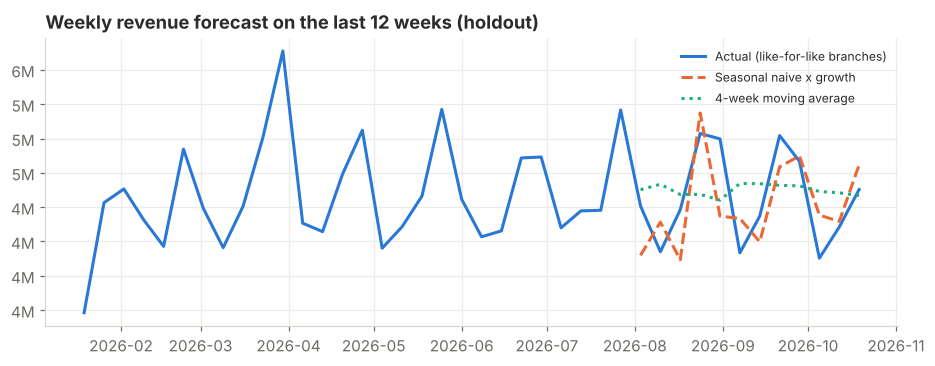

In [6]:
w = query(engine, "SELECT sale_week, SUM(net_revenue) AS rev FROM retail.v_sales_lines WHERE branch_id <> 'BR10' GROUP BY 1 ORDER BY 1")
w["rev"] = w.rev.astype(float); w = w.iloc[1:-1].reset_index(drop=True)   # drop partial first/last weeks
test = w.iloc[-12:]; train = w.iloc[:-12]
ma4 = [w.rev.iloc[i-4:i].mean() for i in test.index]
growth = train.rev.iloc[-12:].sum() / train.rev.iloc[-64:-52].sum()
snaive = [w.rev.iloc[i-52] * growth for i in test.index]
mape = lambda a, f: np.mean(np.abs((np.array(a) - np.array(f)) / np.array(a))) * 100
print(f"MAPE, 4-week moving average: {mape(test.rev, ma4):.1f}%")
print(f"MAPE, seasonal naive x growth: {mape(test.rev, snaive):.1f}%")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(pd.to_datetime(w.sale_week.iloc[-40:]), w.rev.iloc[-40:], color=an.PRIMARY, label="Actual (like-for-like branches)")
ax.plot(pd.to_datetime(test.sale_week), snaive, color=an.HIGHLIGHT, ls="--", label="Seasonal naive x growth")
ax.plot(pd.to_datetime(test.sale_week), ma4, color=an.SECOND, ls=":", label="4-week moving average")
an.kes_axis(ax); ax.set_title("Weekly revenue forecast on the last 12 weeks (holdout)"); ax.legend(fontsize=8)
an.save(fig, "forecast_extension");

Both baselines miss actual weekly revenue by about 5–7% on average (MAPE) on the holdout, with the seasonal baseline doing better. Any more complex model would have to beat these numbers to justify itself. Since the data is synthetic, forecast accuracy here says little about real-world performance. The value of the exercise is the evaluation method, not the score.